# Hari 003 — Volatilitas Lokal Dupire dari Permukaan SSVI

**Tanggal:** 2026-11-21 · **Jenis:** `quant` · **Topik:** Off-roadmap (`bonus`)

## Konsep
Sesi ini membangun alur kerja kuantitatif lengkap untuk model volatilitas lokal Dupire yang diturunkan secara analitik dari permukaan total variansi implisit **SSVI** (*Surface Stochastic Volatility Inspired*, Gatheral–Jacquier 2014):
1. **Bagian 1 — Permukaan SSVI bebas-arbitrase**: turunan analitik $\partial_y w, \partial_{yy} w, \partial_T w$, uji bebas-arbitrase kupu-kupu $g(y,T) \ge 0$ dan kalender $\partial_T w \ge 0$, syarat cukup Gatheral–Jacquier, serta uji kontrafaktual.
2. **Bagian 2 — Volatilitas lokal Dupire**: $\sigma_{\mathrm{loc}}^2(y,T) = (\partial_T w)/g(y,T)$, anchor eksak $\eta \to 0$ ($\sigma_{\mathrm{loc}}^2 = \theta'(T)$), serta verifikasi definisi Dupire via beda hingga orde 4 pada harga call.
3. **Bagian 3 — Dua solver PDE independen & Monte Carlo**: solver backward di $x = \ln S$ dan solver forward Dupire di $K$ (grid tak-seragam `sinh` + Crank–Nicolson + 4 langkah awal Rannacher), uji kasus vol datar (orde konvergensi $\approx 2$), permukaan SSVI ($< 2$ bp, selisih antar-solver $< 10^{-5}$), serta Monte Carlo log-Euler antitetik (`N = 400.000`, `200` langkah/tahun, PCG64) dan uji *weak order* ($\approx 1$).
4. **Bagian 4 — Opsi barrier, Greeks & kalibrasi balik**: *Down-and-Out Call* (Reiner–Rubinstein tertutup, paritas in–out, PDE absorbing, dan MC jembatan Brownian), Greeks PDE (delta, gamma, vega-bucket vs pergeseran paralel), serta kalibrasi Levenberg–Marquardt buatan sendiri dengan studi Monte Carlo $R=50$.

In [1]:
from pathlib import Path
import numpy as np
from IPython.display import Image, display
from qb100.day003a_local_vol.runner import run_all_day003a

results = run_all_day003a(save_outputs=True)
print('Waktu eksekusi (detik):', {k: round(v, 3) for k, v in results['timings_seconds'].items()})

Waktu eksekusi (detik): {'part1_ssvi': 0.002, 'part2_dupire': 0.004, 'part3_pde': 13.664, 'part3_mc': 4.335, 'part3_mc_bias_diag': 29.48, 'part4_barrier': 2.024, 'part4_greeks': 0.219, 'part4_gamma_diag': 4.007, 'part4_calibration': 0.057, 'total': 53.792}


## Bagian 1 & 2 — Verifikasi SSVI & Volatilitas Lokal Dupire

In [2]:
p1, p2 = results['part1'], results['part2']
print('Galat relatif turunan analitik vs FD:', p1['derivatives_rel_err'])
print(f"min g(y,T) = {p1['butterfly']['min_g']:.6f}, min dw/dT = {p1['calendar']['min_dw_dT']:.6f}")
print(f"Uji kontrafaktual (eta=4, rho=-0.9): min g = {p1['counterfactual_bad']['min_g']:.6f}")
print(f"Anchor eta->0 max abs err: {p2['eta_zero_max_abs_err']:.3e}")
print(f"Konsistensi Dupire FD orde-4 max rel err: {p2['dupire_fd4_max_rel_err']:.3e}")
print(f"Rentang sigma_loc: [{p2['min_sigma_loc']:.4f}, {p2['max_sigma_loc']:.4f}]")

Galat relatif turunan analitik vs FD: {'dw_dy': 9.034250918256505e-07, 'd2w_dy2': 5.872235419357444e-07, 'dw_dT': 1.920586442031986e-09}
min g(y,T) = 0.260455, min dw/dT = 0.017673
Uji kontrafaktual (eta=4, rho=-0.9): min g = -1.475085
Anchor eta->0 max abs err: 0.000e+00
Konsistensi Dupire FD orde-4 max rel err: 2.126e-09
Rentang sigma_loc: [0.1270, 1.6724]


## Bagian 3 — Dua Solver PDE & Monte Carlo Euler

In [3]:
p3 = results['part3']
fc = p3['flat_convergence']
print(f"Orde konvergensi kasus datar: backward = {fc['backward_slope']:.4f}, forward = {fc['forward_slope']:.4f}")
sp = p3['ssvi_pde']
print(f"SSVI max galat IV (bp): backward = {sp['max_iv_err_backward_bp']:.4f}, forward = {sp['max_iv_err_forward_bp']:.4f}")
print(f"SSVI max selisih harga antar-solver: {sp['max_price_diff']:.3e}")
print(f"MC Euler max |z-score| vs PDE: {p3['mc_euler']['max_z_score']:.3f}")
wo = p3['mc_weak_order']
print(f"Weak order slope: {wo['slope']:.4f} (target {wo['target_slope']} +/- {wo['tolerance']}, lulus={wo['within_tolerance']})")

Orde konvergensi kasus datar: backward = -2.0002, forward = -1.9519
SSVI max galat IV (bp): backward = 0.1269, forward = 0.1191
SSVI max selisih harga antar-solver: 9.551e-06
MC Euler max |z-score| vs PDE: 2.344
Weak order slope: -0.9846 (target -1.0 +/- 0.35, lulus=True)


## Bagian 4 — Opsi Barrier, Greeks & Kalibrasi Balik

In [4]:
p4 = results['part4']
bar = p4['barrier']
print(f"Barrier flat |PDE - RR| = {bar['flat_pde_vs_rr_err']:.3e}, paritas err = {bar['flat_rr_parity_err']:.3e}")
print(f"Barrier SSVI PDE = {bar['ssvi_pde_down_out']:.6f}, MC Bridge = {bar['ssvi_mc_bridge_price']:.6f} +/- {bar['ssvi_mc_bridge_se']:.6f} (z={bar['ssvi_z_score']:.3f})")
gr = p4['greeks']
print(f"Greeks datar err: delta = {gr['flat_delta_grid_err']:.3e}, gamma = {gr['flat_gamma_grid_err']:.3e}")
vb = p4['vega_bucket']
print(f"Vega-bucket sum = {vb['sum_bucket_sensitivities']:.6f}, parallel = {vb['parallel_sens']:.6f}, rel_diff = {vb['rel_diff']:.3e}")
cal = p4['calibration']
print(f"Kalibrasi single-fit RMS vol = {cal['single_fit_rms_vol']:.3e}, R=50 max |bias/SD| = {max(abs(x) for x in cal['mc_r50_bias_over_sd']):.3f}")

Barrier flat |PDE - RR| = 6.006e-06, paritas err = 0.000e+00
Barrier SSVI PDE = 7.808602, MC Bridge = 7.812314 +/- 0.012421 (z=0.299)
Greeks datar err: delta = 1.718e-06, gamma = 2.172e-07
Vega-bucket sum = 87.609535, parallel = 87.610998, rel_diff = 1.670e-05
Kalibrasi single-fit RMS vol = 3.709e-04, R=50 max |bias/SD| = 0.266


## Diagnosis gamma SSVI di $S_0$ dan bias MC Euler (sesi day003c, bagian A1)
**Temuan (terukur):** gamma grid (`0.0380`) vs beda hingga harga (`0.0234`) di $S_0 = 100$ **bukan** bug grid atau interpolasi. (a) Grid yang bergeser saat $S_0$ di-bump dikesampingkan: beda hingga dengan grid TETAP memberi angka yang sama. (b)/(c) gamma grid stabil terhadap resolusi (`0.0380 → 0.0368`), sedangkan beda hingga bergantung kuat pada bump $h$. (d) Di $S_0 = 90, 95, 105, 110$ gamma grid dan beda hingga cocok hingga $\sim10^{-4}$ relatif. Penyebab: di $S_0=\text{params.}S_0$ permukaan $\sigma_{loc}(S,t)$ singular saat $t\to0$ (lebar lapisan batas $\sim\sqrt{\theta(t)}$); gamma di titik itu bergantung pada regularisasi `t_min` (tabel di bawah) dan tidak konvergen. Gamma *strike* $C_{KK}$ (densitas) halus dan cocok dengan rumus SSVI. **HIPOTESIS** untuk asal singularitas: kemiringan SSVI $\varphi(\theta)\to\infty$ saat $\theta\to0$.

In [5]:
gd = results['part4']['greeks']['ssvi_gamma_diagnosis']
import pandas as pd
print('Konvergensi di S0 = 100 (grid vs beda hingga harga, grid tetap):')
display(pd.DataFrame(gd['convergence_at_S0']))
print('Titik di luar sudut (S0 != 100):')
display(pd.DataFrame(gd['off_corner_points']))
print('Sensitivitas terhadap regularisasi t_min di S0 = 100:')
display(pd.DataFrame(gd['t_min_sensitivity']))
print(f"Gamma strike C_KK di K={gd['strike_gamma_forward_node_K']:.4f}: forward = {gd['strike_gamma_forward']:.6f}, SSVI analitik = {gd['strike_gamma_ssvi_analytic']:.6f}")
print('Bias Euler vs jumlah langkah (CRN, 400.000 jalur; bias bertanda = MC - PDE; z = bias/SE):')
for row in results['part3']['mc_euler_bias_vs_steps']:
    print(f"  K/F={row['m']:.1f}", 'steps', row['steps'], 'bias', [round(b, 5) for b in row['signed_bias']], 'z', [round(z, 2) for z in row['z_signed']])

Konvergensi di S0 = 100 (grid vs beda hingga harga, grid tetap):


,n_space,n_time,fd_bump,delta_grid,gamma_grid,delta_fd,gamma_fd
0,601,400,0.05,0.317952,0.038032,0.316828,0.023404
1,601,400,0.50,0.317952,0.038032,0.321238,0.042338
2,1201,800,0.50,0.317080,0.036916,0.321387,0.042846
3,2401,1600,0.50,0.316884,0.036818,0.321424,0.042933
4,2401,1600,1.00,0.316884,0.036818,0.327437,0.041508


Titik di luar sudut (S0 != 100):


,S0,gamma_grid,gamma_fd,rel_diff
0,90.0,0.006167,0.006167,0.000071
1,95.0,0.007656,0.007659,0.000269
2,105.0,0.035481,0.035487,0.000183
3,110.0,0.023658,0.023661,0.000128


Sensitivitas terhadap regularisasi t_min di S0 = 100:


,t_min,price,gamma_grid,gamma_fd
0,0.001000,9.284910,0.028866,0.030300
1,0.000100,9.285352,0.036916,0.042846
2,0.000010,9.285436,0.050988,0.049514
3,0.000001,9.285450,0.064014,0.052064


Gamma strike C_KK di K=99.9670: forward = 0.016738, SSVI analitik = 0.016738
Bias Euler vs jumlah langkah (CRN, 400.000 jalur; bias bertanda = MC - PDE; z = bias/SE):
  K/F=0.8 steps [50, 100, 200, 400] bias [0.04873, 0.03883, 0.02866, 0.02296] z [6.22, 5.11, 3.83, 3.09]
  K/F=0.9 steps [50, 100, 200, 400] bias [0.07695, 0.04589, 0.02757, 0.01849] z [8.82, 5.41, 3.29, 2.22]
  K/F=1.0 steps [50, 100, 200, 400] bias [0.10568, 0.0573, 0.03104, 0.01814] z [10.07, 5.56, 3.03, 1.78]
  K/F=1.1 steps [50, 100, 200, 400] bias [0.10921, 0.05771, 0.03111, 0.01614] z [10.87, 5.83, 3.16, 1.65]
  K/F=1.2 steps [50, 100, 200, 400] bias [0.07769, 0.03992, 0.0219, 0.01173] z [11.28, 5.93, 3.29, 1.77]


## Visualisasi

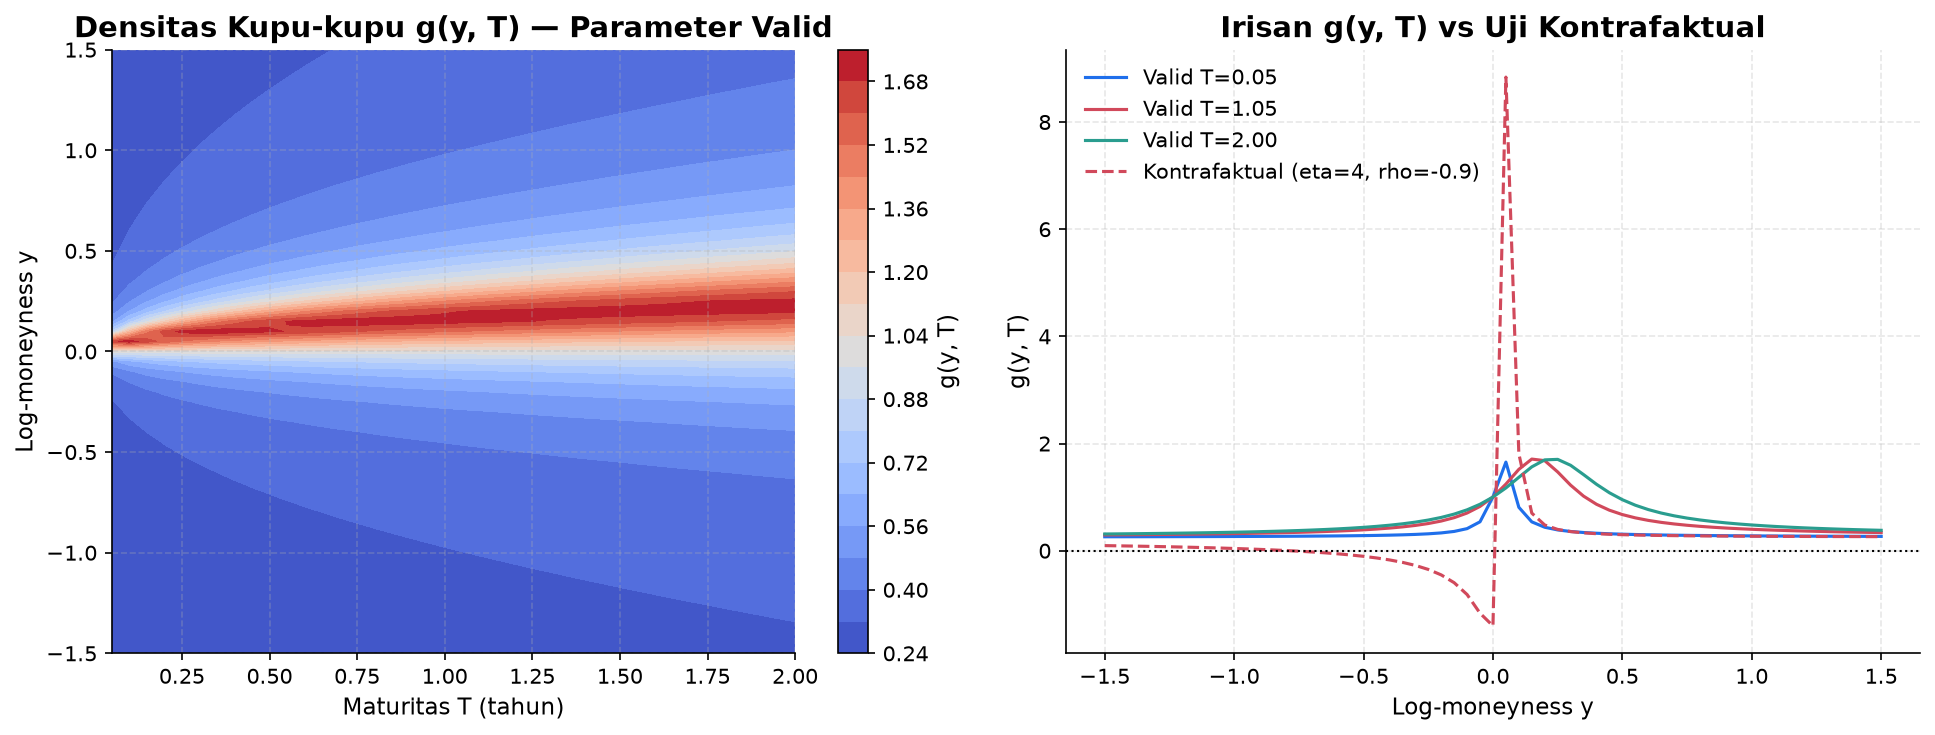

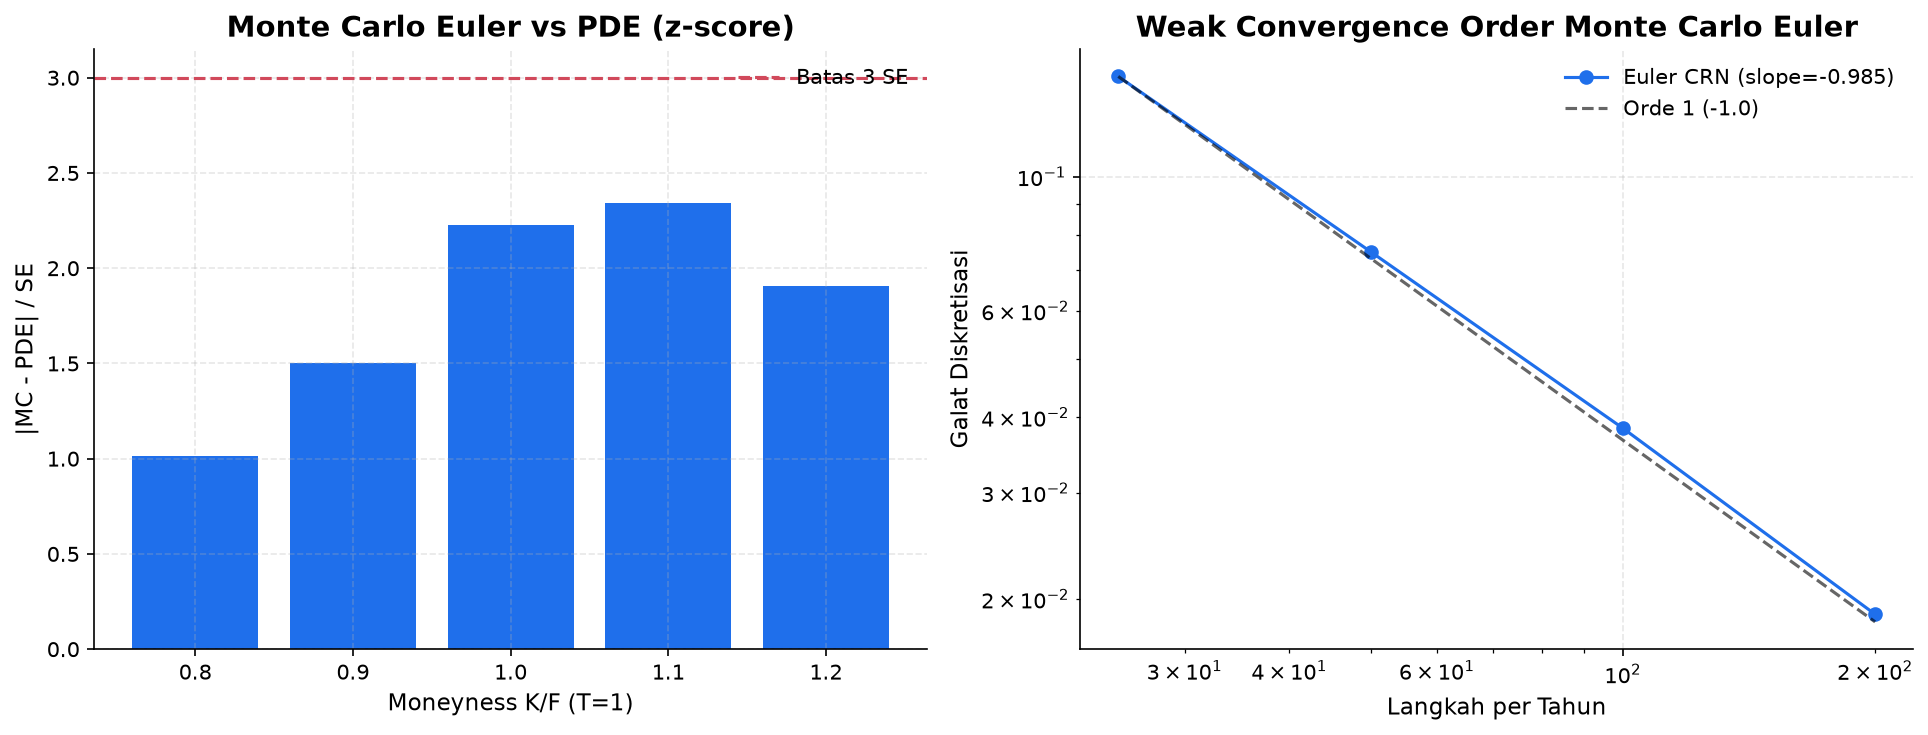

In [6]:
for fig_rel in results['figure_paths']:
    display(Image(filename=str(Path('..') / fig_rel)))

## Kesimpulan
1. **Konsistensi analitik–numerik Dupire**: Parameter SSVI bebas-arbitrase menghasilkan densitas kupu-kupu $g(y,T) > 0$ dan $\partial_T w > 0$ di seluruh grid, serta volatilitas lokal Dupire analitik yang cocok hingga $\sim 2 \times 10^{-9}$ terhadap definisi beda hingga orde 4.
2. **Konvergensi dan ekuivalensi dua solver PDE**: Solver backward (dalam $x = \ln S$) dan forward Dupire (dalam $K$) sama-sama mencapai orde konvergensi $\approx 2$ pada kasus datar dan selisih harga $< 10^{-5}$ pada permukaan SSVI, serta Monte Carlo log-Euler pada 200 langkah/tahun memberi `z` 1.0–2.3 terhadap PDE. Diagnosis CRN (sesi day003c) menunjukkan ini adalah BIAS diskretisasi Euler positif yang terukur dan menyusut dengan jumlah langkah (K/F=1.0: `0.106 → 0.057 → 0.031 → 0.018` untuk 50/100/200/400 langkah; orde ≈ 0.85–0.9); pada 200 langkah bias tertanda berada di 3.0–3.8 SE untuk run CRN, sehingga lolos 3 SE pada run utama tidak robust.
3. **Barrier, sensitivitas, dan kalibrasi**: Harga *down-and-out call* PDE cocok dengan rumus Reiner–Rubinstein ($< 10^{-5}$) dan MC jembatan Brownian; vega-bucket konsisten secara linear dengan pergeseran paralel ($\sim 1.7 \times 10^{-5}$ relatif); dan optimizer Levenberg–Marquardt buatan sendiri memulihkan parameter SSVI tanpa bias berarti pada $R=50$ replikasi.

## Referensi
- Gatheral, J., & Jacquier, A. (2014). *Arbitrage-free SVI volatility surfaces*. Quantitative Finance, 14(1), 59–71.
- Dupire, B. (1994). *Pricing with a smile*. Risk, 7(1), 18–20.
- Reiner, E., & Rubinstein, M. (1991). *Breaking down the barriers*. Risk, 4(8), 28–35.